<a href="https://colab.research.google.com/github/padayatti1/Small-Molecule-drug-discovery-/blob/main/ADMET_Day2_Practical_Annotated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 2 Practical Workshop: ADMET Calculation Pipeline in Google Colab

**Theme:** from database molecules or user-uploaded SMILES to descriptor calculation, 2D/3D visualization, ADMET rule filtering, publication-quality plots, and candidate ranking.

This notebook is designed for a student-facing ADMET practical session. It has two input modes:

1. **Fetch 200 molecules from ChEMBL** directly inside Colab.
2. **Upload your own CSV file** containing molecule names and SMILES.

The notebook uses **RDKit**, **py3Dmol**, **matplotlib**, **Plotly**, and **scikit-learn**.

> Important teaching note: this notebook calculates physicochemical descriptors, drug-likeness rules, and descriptor-based ADMET proxy flags. It is not a replacement for experimentally validated ADMET assays or endpoint-specific production models.

> **Discovery Boulevard Training Series | 3-Day ADMET & ML Drug Discovery Training**
>
> This is the annotated class version. Every code cell is preceded by an *Explanatory note* (what the cell does, why, and the real result from the reference run) and starts with a `# STEP` comment. Data are read from the frozen `Demo_Data/` folder by default, so your numbers should match the notes exactly. Docking poses and scores may differ slightly between machines; that is expected.
>
> Companion manual: **DB-TM-ADMET-03 ADMET Practical Code Companion**.

## 1. Install packages

Run this cell first. If Colab asks to restart the runtime after installing RDKit, restart and run the notebook again from this cell.

### Explanatory note: Package installation
**What it does:** installs RDKit (chemistry), the ChEMBL web client, py3Dmol (3D viewer), Plotly, scikit-learn, openpyxl (Excel export) and tabulate (markdown tables).

**Why:** Colab starts from a clean machine each session. `tabulate` is required by `DataFrame.to_markdown()` in the export step; without it the summary export crashes outside Colab.

**Real example (reference run):** all packages installed in about 40 s on a standard Colab runtime.

In [9]:
# STEP 1 | install the Python libraries used by this notebook
!pip -q install rdkit chembl_webresource_client py3Dmol plotly scikit-learn openpyxl tabulate

## 2. Import libraries and set plotting style

### Explanatory note: Imports and plotting style
**What it does:** loads every library once and sets one consistent figure style and colour palette.

**Why:** importing at the top makes missing packages fail immediately rather than halfway through the pipeline; a shared style makes all figures publication-ready.

**Real example (reference run):** figures are saved at 300 dpi into `figures/`; tables go to `outputs/`.

In [10]:
# STEP 2 | import libraries, create output folders, set figure style
import os
import math
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from IPython.display import display, HTML

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, AllChem, Draw, QED
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem import rdFingerprintGenerator

import matplotlib.pyplot as plt
import matplotlib as mpl
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import py3Dmol

# Output folders
os.makedirs("outputs", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Publication-like plotting defaults
mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
})

# Consistent accent palette
NAVY = "#183A59"
TEAL = "#00A6A6"
ORANGE = "#F2A541"
RED = "#C94C4C"
GRAY = "#6B7280"
LIGHT = "#F7FAFC"

### Explanatory note: demo data or live data?
**What it does:** chooses where the input molecules come from.

**Why:** live web services (ChEMBL, ZINC on GitHub, the PDB) change over time and can be slow or offline during a class. The `Demo_Data/` folder holds the exact files downloaded for the reference run, so every student gets the same molecules and the same numbers.

**How to use it:** keep `DATA_SOURCE = "demo"` in class. On Google Colab, upload `Demo_Data.zip` when asked (or put `Demo_Data/` in *MyDrive*). Switch to `"live"` at home to repeat the analysis on today's database.

In [11]:
# =====================================================================
# DATA SOURCE SWITCH  (Discovery Boulevard practical class)
#   "demo" : read the frozen files in Demo_Data/  -> works offline and
#            reproduces the reference run exactly
#   "live" : download fresh data from the internet -> numbers can drift
#            as ChEMBL / ZINC / PDB are updated
# =====================================================================
DATA_SOURCE = "live"

from pathlib import Path
import zipfile

def find_demo_dir():
    """Locate Demo_Data/ locally, on Colab, or in Google Drive; on Colab, offer an upload."""
    for cand in [Path("Demo_Data"), Path("../Demo_Data"), Path("/content/Demo_Data"),
                 Path("/content/drive/MyDrive/Demo_Data")]:
        if cand.exists():
            return cand.resolve()
    try:
        from google.colab import files          # only available on Colab
        print("Demo_Data not found. Please upload Demo_Data.zip (provided by the instructor).")
        uploaded = files.upload()
        zipfile.ZipFile(next(iter(uploaded))).extractall("/content")
        return Path("/content/Demo_Data")
    except ImportError:
        raise FileNotFoundError("Put the Demo_Data folder next to this notebook, or set DATA_SOURCE = 'live'.")

DEMO_DIR = find_demo_dir() if DATA_SOURCE == "demo" else None
print("Data source:", DATA_SOURCE, "|", DEMO_DIR if DEMO_DIR else "internet")


Data source: live | internet


## 3. Choose input mode

Set `INPUT_MODE` to:

- `"chembl"` to fetch 200 molecules from ChEMBL.
- `"upload"` to upload your own CSV file.

For uploaded files, the CSV should contain at least a **SMILES** column. A **Molecule** column is recommended but not mandatory.

### Explanatory note: Input mode
**What it does:** selects between the 200 ChEMBL reference drugs (`"chembl"`) and your own CSV (`"upload"`).

**Why:** the same pipeline should work on any library, so the source of molecules is a single switch.

**Real example (reference run):** `INPUT_MODE = "chembl"` with `max_phase = 4` (approved drugs) was used.

In [13]:
# STEP 3 | choose where the molecules come from
INPUT_MODE = "chembl"   # options: "chembl" or "upload"
N_CHEMBL_MOLECULES = 200

# Optional: use only approved/late-stage molecules when possible.
# max_phase=4 means approved drugs in ChEMBL. If too few are retrieved, the notebook falls back to general small molecules.
CHEMBL_MAX_PHASE_FILTER = 4

assert INPUT_MODE in ["chembl", "upload"], "INPUT_MODE must be 'chembl' or 'upload'."

## 4A. Option A — Fetch 200 reference molecules from ChEMBL

This section uses the official ChEMBL web-resource client to retrieve molecules programmatically. The pipeline tries to fetch approved small molecules first, then falls back to general ChEMBL small molecules if needed.

### Explanatory note: Getting molecules from ChEMBL (or the demo file)
**What it does:** asks the ChEMBL API for approved small molecules and keeps their ChEMBL ID, name and canonical SMILES. In demo mode it simply reads `Demo_Data/day2/chembl_approved_drugs_200.csv`.

**Why:** approved drugs are a realistic reference set: most should pass the rules, and the failures are instructive.

**Real example (reference run):** 200 molecules loaded, the first rows include PRAZOSIN, NICOTINE and OFLOXACIN.

In [15]:
# STEP 4A | fetch 200 approved drugs from ChEMBL (live) or read the frozen demo file
def fetch_chembl_molecules(n=200, max_phase=4):
    # Fetch molecules with canonical SMILES from ChEMBL.
    from chembl_webresource_client.new_client import new_client

    molecule_client = new_client.molecule

    def _collect(query, n):
        rows = []
        fields = [
            "molecule_chembl_id",
            "pref_name",
            "molecule_type",
            "molecule_structures",
            "max_phase",
            "therapeutic_flag",
        ]
        records = query.only(fields)
        for rec in records:
            if len(rows) >= n:
                break
            structures = rec.get("molecule_structures") or {}
            smiles = structures.get("canonical_smiles")
            if not smiles:
                continue
            rows.append({
                "Molecule_ID": rec.get("molecule_chembl_id"),
                "Molecule": rec.get("pref_name") or rec.get("molecule_chembl_id"),
                "SMILES": smiles,
                "Source": "ChEMBL",
                "Max_Phase": rec.get("max_phase"),
                "Therapeutic_Flag": rec.get("therapeutic_flag"),
            })
        return pd.DataFrame(rows)

    if max_phase is not None:
        query = molecule_client.filter(
            molecule_type="Small molecule",
            molecule_structures__isnull=False,
            max_phase=max_phase,
        )
        df = _collect(query, n)
        if len(df) >= min(50, n):
            return df.head(n).reset_index(drop=True)

    # Fallback: general ChEMBL small molecules with structures
    query = molecule_client.filter(
        molecule_type="Small molecule",
        molecule_structures__isnull=False,
    )
    df = _collect(query, n)
    return df.head(n).reset_index(drop=True)

if INPUT_MODE == "chembl":
    if DATA_SOURCE == "demo":
        # frozen copy of the ChEMBL download used in the reference run
        raw_df = pd.read_csv(DEMO_DIR / "day2" / "chembl_approved_drugs_200.csv")
        print(f"Loaded {len(raw_df)} molecules from Demo_Data (ChEMBL, approved drugs).")
    else:
        try:
            raw_df = fetch_chembl_molecules(N_CHEMBL_MOLECULES, CHEMBL_MAX_PHASE_FILTER)
            print(f"Fetched {len(raw_df)} molecules from ChEMBL.")
        except Exception as e:
            print(f"ChEMBL live API is currently unavailable ({type(e).__name__}). Falling back to local Demo_Data backup...")
            # Attempt to use local demo fallback path
            try:
                from pathlib import Path
                fallback_path = Path("Demo_Data/day2/chembl_approved_drugs_200.csv")
                if not fallback_path.exists():
                     # Search common folders if Demo_Data is located elsewhere
                     for cand in [Path("../Demo_Data"), Path("/content/Demo_Data")]:
                         if cand.exists():
                             fallback_path = cand / "day2" / "chembl_approved_drugs_200.csv"
                             break
                raw_df = pd.read_csv(fallback_path)
                raw_df["Source"] = "ChEMBL (Backup)"
                print(f"Successfully loaded {len(raw_df)} fallback molecules from local Demo_Data.")
            except Exception as fe:
                raise RuntimeError("Both ChEMBL live service and local Demo_Data fallback files are unavailable.") from fe
    display(raw_df.head())

ChEMBL live API is currently unavailable (HttpApplicationError). Falling back to local Demo_Data backup...


RuntimeError: Both ChEMBL live service and local Demo_Data fallback files are unavailable.

## 4B. Option B — Upload your own CSV file

The uploaded file should have a column named **SMILES**. If it does not have a **Molecule** column, molecule names will be generated automatically.

### Explanatory note: Uploading your own molecules
**What it does:** lets you upload a CSV that has at least a `SMILES` column; names are generated if missing.

**Why:** students can rerun the full pipeline on their own project molecules after the class.

**Real example (reference run):** skipped in the test run because `INPUT_MODE = "chembl"`.

In [8]:
# STEP 4B | optional: use your own CSV of SMILES
if INPUT_MODE == "upload":
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]

    raw_df = pd.read_csv(file_name)
    if "SMILES" not in raw_df.columns:
        raise ValueError("Uploaded file must contain a column named 'SMILES'.")
    if "Molecule" not in raw_df.columns:
        raw_df["Molecule"] = [f"Mol_{i+1}" for i in range(len(raw_df))]
    if "Source" not in raw_df.columns:
        raw_df["Source"] = "User upload"

    print(f"Uploaded {len(raw_df)} molecules.")
    display(raw_df.head())

## 5. Validate, standardize, and clean SMILES

This step performs the basic structure quality control needed before descriptor calculation.

Operations performed:

- Convert SMILES to RDKit molecule objects.
- Remove invalid SMILES.
- Keep the largest fragment when salts or mixtures are present.
- Neutralize charges when possible.
- Generate canonical SMILES.
- Remove duplicate molecules.

### Explanatory note: Structure curation
**What it does:** parses each SMILES, cleans it, keeps the largest fragment (removes salts and counter-ions), neutralises charges and removes duplicates by canonical SMILES.

**Why:** descriptors are only meaningful for the parent drug; `VALPROATE SODIUM` must be scored as valproic acid, and the same molecule entered twice would bias every statistic.

**Real example (reference run):** 200 molecules in, 0 invalid, 2 duplicates removed, 198 clean unique molecules out (for example ofloxacin and levofloxacin collapse only if stereochemistry is lost).

In [10]:
# STEP 5 | validate, standardise and de-duplicate the structures
lfc = rdMolStandardize.LargestFragmentChooser()
uncharger = rdMolStandardize.Uncharger()


def mol_from_smiles(smiles):
    try:
        if pd.isna(smiles):
            return None
        return Chem.MolFromSmiles(str(smiles))
    except Exception:
        return None


def standardize_mol(mol):
    if mol is None:
        return None
    try:
        mol = rdMolStandardize.Cleanup(mol)
        mol = lfc.choose(mol)
        mol = uncharger.uncharge(mol)
        Chem.SanitizeMol(mol)
        return mol
    except Exception:
        return None


def canonical_smiles(mol):
    try:
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return None

work_df = raw_df.copy()
work_df["Original_SMILES"] = work_df["SMILES"].astype(str)
work_df["Mol_raw"] = work_df["Original_SMILES"].apply(mol_from_smiles)
work_df["Mol"] = work_df["Mol_raw"].apply(standardize_mol)

invalid_df = work_df[work_df["Mol"].isna()].copy()
clean_df = work_df[work_df["Mol"].notna()].copy()
clean_df["Canonical_SMILES"] = clean_df["Mol"].apply(canonical_smiles)
clean_df = clean_df.dropna(subset=["Canonical_SMILES"])
clean_df = clean_df.drop_duplicates("Canonical_SMILES").reset_index(drop=True)

print(f"Original molecules: {len(raw_df)}")
print(f"Invalid molecules removed: {len(invalid_df)}")
print(f"Clean unique molecules retained: {len(clean_df)}")

display(clean_df[["Molecule", "Canonical_SMILES", "Source"]].head())

invalid_df.drop(columns=[c for c in ["Mol_raw", "Mol"] if c in invalid_df.columns]).to_csv(
    "outputs/invalid_molecules.csv", index=False
)

[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normali

Original molecules: 200
Invalid molecules removed: 0
Clean unique molecules retained: 198


[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChooser
[15:32:43] Running Uncharger
[15:32:43] Initializing MetalDisconnector
[15:32:43] Running MetalDisconnector
[15:32:43] Initializing Normalizer
[15:32:43] Running Normalizer
[15:32:43] Running LargestFragmentChoo

,Molecule,Canonical_SMILES,Source
0,PRAZOSIN,COc1cc2nc(N3CCN(C(=O)c4ccco4)CC3)nc(N)c2cc1OC,ChEMBL
1,NICOTINE,CN1CCC[C@H]1c1cccnc1,ChEMBL
2,OFLOXACIN,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,ChEMBL
3,NALIDIXIC ACID,CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21,ChEMBL
4,INDOMETHACIN,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,ChEMBL


## 6. 2D molecule visualization

A quick structure grid helps students visually inspect the molecule set before looking at numerical descriptors.

### Explanatory note: 2D structure grid
**What it does:** draws the first 30 cleaned molecules in a 5 x 6 grid with their names.

**Why:** a quick visual check catches unusual chemistry (metals, peptides, fragments) before any number is trusted.

**Real example (reference run):** the grid starts with PRAZOSIN, NICOTINE, OFLOXACIN, NALIDIXIC ACID and INDOMETHACIN.

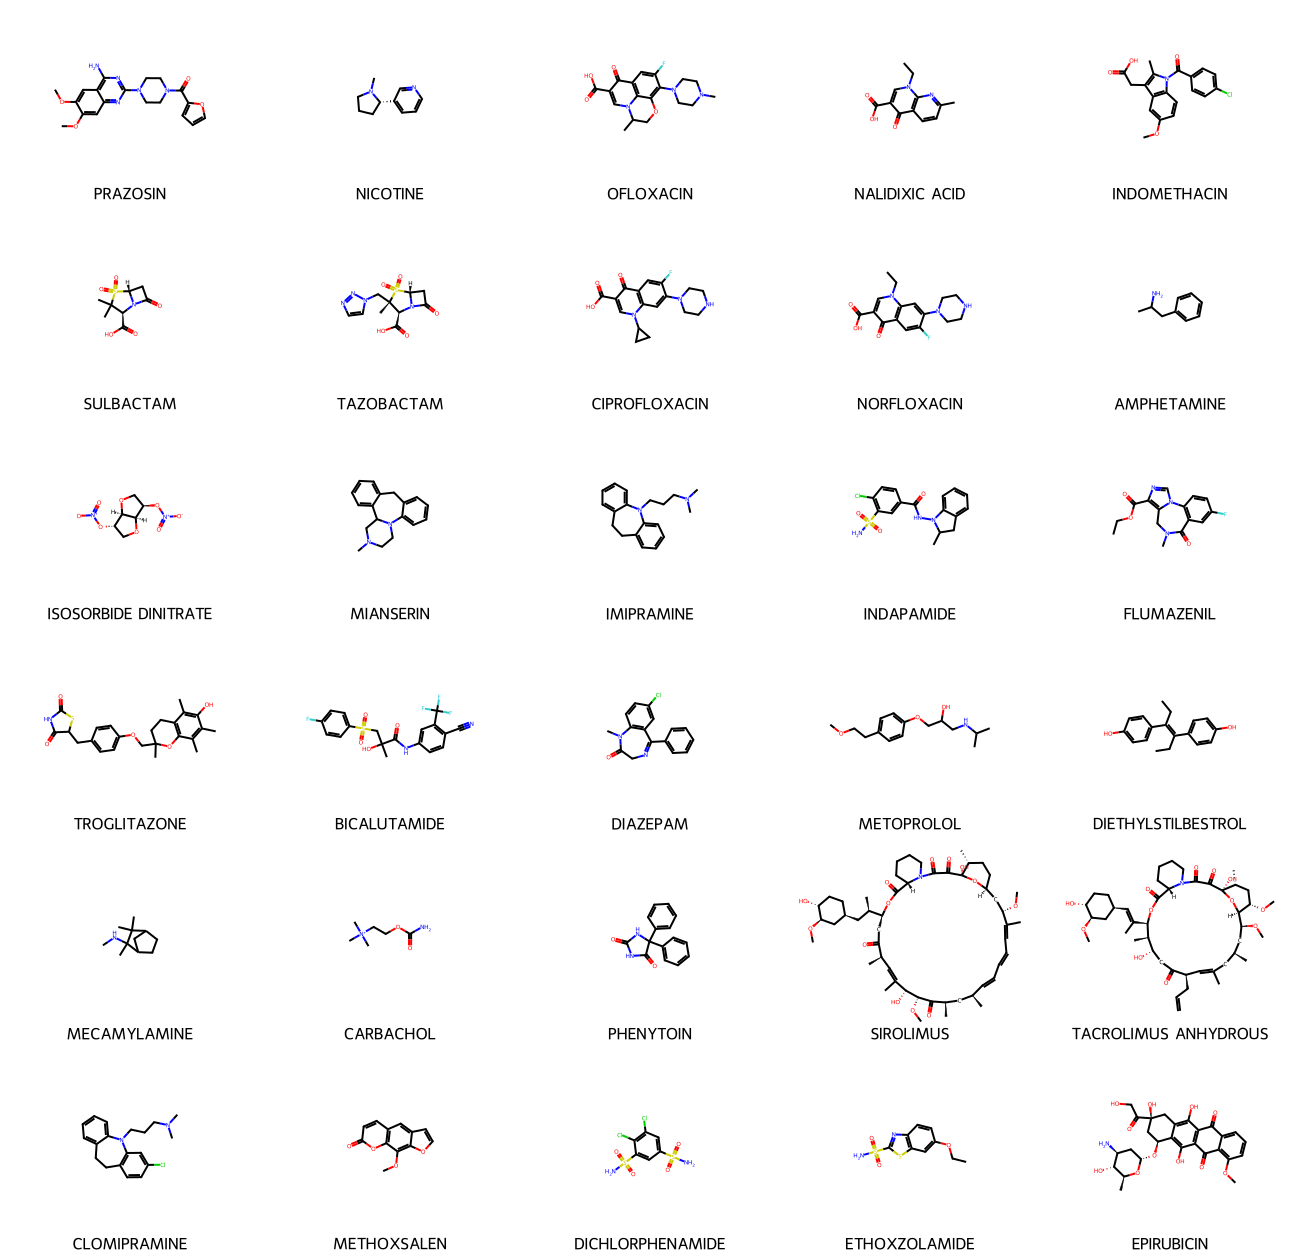

In [11]:
# STEP 6 | visual sanity check of the cleaned library
# Draw first 30 molecules for readability
n_draw = min(30, len(clean_df))
mols_2d = clean_df["Mol"].head(n_draw).tolist()
legends = clean_df["Molecule"].head(n_draw).astype(str).tolist()

img = Draw.MolsToGridImage(
    mols_2d,
    molsPerRow=5,
    subImgSize=(260, 210),
    legends=legends,
    useSVG=False,
)

display(img)


## 7. Generate 3D conformers

RDKit can generate approximate 3D conformers using distance geometry and then optimize them using MMFF or UFF force fields.

### Explanatory note: 3D conformer generation
**What it does:** adds hydrogens, embeds a 3D geometry with ETKDGv3 (random seed 42) and relaxes it with the MMFF94 force field (UFF as fallback).

**Why:** molecules are 3D objects: shape and flexibility explain permeability and binding, and the same 3D routine is reused before docking on Day 3.

**Real example (reference run):** 3D conformers generated for the first 10 molecules in under a second.

In [12]:
# STEP 7 | generate one optimised 3D conformer per molecule
def generate_3d_mol(mol, seed=42, max_iters=500):
    # Generate one optimized 3D conformer for a molecule.
    mol_h = Chem.AddHs(mol)
    params = AllChem.ETKDGv3()
    params.randomSeed = seed
    status = AllChem.EmbedMolecule(mol_h, params)

    # Fallback if embedding fails
    if status != 0:
        status = AllChem.EmbedMolecule(mol_h, randomSeed=seed, useRandomCoords=True)

    if status != 0:
        return None

    try:
        if AllChem.MMFFHasAllMoleculeParams(mol_h):
            AllChem.MMFFOptimizeMolecule(mol_h, maxIters=max_iters)
        else:
            AllChem.UFFOptimizeMolecule(mol_h, maxIters=max_iters)
    except Exception:
        try:
            AllChem.UFFOptimizeMolecule(mol_h, maxIters=max_iters)
        except Exception:
            pass
    return mol_h

# Generate 3D structures for a small subset first to keep the live demo fast.
N_3D = min(10, len(clean_df))
clean_df["Mol3D"] = None
for i in range(N_3D):
    clean_df.at[i, "Mol3D"] = generate_3d_mol(clean_df.at[i, "Mol"])

print(f"Generated 3D conformers for {N_3D} molecules.")

Generated 3D conformers for 10 molecules.


## 8. Interactive 3D molecule visualization with py3Dmol

Change `SELECTED_INDEX` to visualize a different molecule from the first 3D-generated subset.

### Explanatory note: Interactive 3D viewer
**What it does:** shows one 3D conformer in the browser as ball-and-stick with a transparent surface.

**Why:** rotating a molecule makes size, polarity and flexibility intuitive before we turn them into numbers.

**Real example (reference run):** `SELECTED_INDEX = 5` shows SULBACTAM (MW 233.2, TPSA 91.8 A2).

In [17]:
# STEP 8 | look at a molecule in 3D (change SELECTED_INDEX to explore)
def show_py3dmol(mol3d, style="stick", show_surface=False, width=700, height=450):
    if mol3d is None:
        raise ValueError("No 3D molecule available.")
    mol_block = Chem.MolToMolBlock(mol3d)
    view = py3Dmol.view(width=width, height=height)
    view.addModel(mol_block, "mol")

    if style == "stick":
        view.setStyle({"stick": {"radius": 0.18}})
    elif style == "ballstick":
        view.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.28}})
    elif style == "sphere":
        view.setStyle({"sphere": {"scale": 0.35}})
    else:
        view.setStyle({"stick": {}})

    if show_surface:
        view.addSurface(py3Dmol.VDW, {"opacity": 0.35, "color": "white"})

    view.setBackgroundColor("white")
    view.zoomTo()
    return view.show()

SELECTED_INDEX = 7
print(clean_df.loc[SELECTED_INDEX, ["Molecule", "Canonical_SMILES"]])
show_py3dmol(clean_df.loc[SELECTED_INDEX, "Mol3D"], style="ballstick", show_surface=True)

Molecule                                         CIPROFLOXACIN
Canonical_SMILES    O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O
Name: 7, dtype: object


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 9. Calculate core ADMET-related descriptors

These descriptors are the first computational language of ADMET.

### Explanatory note: Core ADMET descriptors
**What it does:** computes 14 descriptors per molecule with RDKit: MW, cLogP, molar refractivity, TPSA, HBD, HBA, rotatable bonds, ring counts, formal charge, fraction Csp3, heavy atoms and QED.

**Why:** these numbers are the computational language of ADMET: size, lipophilicity, polarity and flexibility control solubility, permeability, metabolism and toxicity risk.

**Real example (reference run):** PAROXETINE: MW 329.37, cLogP 3.33, TPSA 39.7, HBD 1, HBA 4, RotB 4, QED 0.93. SIROLIMUS: MW 914.19, cLogP 6.18, TPSA 195.4.

In [18]:
# STEP 9 | calculate the descriptor table
def calculate_descriptors(mol):
    return {
        "MW": Descriptors.MolWt(mol),
        "cLogP": Crippen.MolLogP(mol),
        "MolMR": Crippen.MolMR(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotB": Lipinski.NumRotatableBonds(mol),
        "Aromatic_Rings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "Aliphatic_Rings": rdMolDescriptors.CalcNumAliphaticRings(mol),
        "Total_Rings": rdMolDescriptors.CalcNumRings(mol),
        "Formal_Charge": Chem.GetFormalCharge(mol),
        "Fraction_Csp3": rdMolDescriptors.CalcFractionCSP3(mol),
        "Heavy_Atoms": Descriptors.HeavyAtomCount(mol),
        "QED": QED.qed(mol),
    }

desc_df = pd.DataFrame(clean_df["Mol"].apply(calculate_descriptors).tolist())

base_cols = [c for c in ["Molecule_ID", "Molecule", "Source", "Max_Phase", "Therapeutic_Flag", "Canonical_SMILES"] if c in clean_df.columns]
result_df = pd.concat([clean_df[base_cols].reset_index(drop=True), desc_df], axis=1)

# Round numeric descriptor columns for display/export readability
numeric_cols = desc_df.columns.tolist()
result_df[numeric_cols] = result_df[numeric_cols].round(3)

display(result_df.head())

,Molecule_ID,Molecule,Source,Max_Phase,Therapeutic_Flag,Canonical_SMILES,MW,cLogP,MolMR,TPSA,HBD,HBA,RotB,Aromatic_Rings,Aliphatic_Rings,Total_Rings,Formal_Charge,Fraction_Csp3,Heavy_Atoms,QED
0,CHEMBL2,PRAZOSIN,ChEMBL,4.0,True,COc1cc2nc(N3CCN(C(=O)c4ccco4)CC3)nc(N)c2cc1OC,383.408,1.785,103.879,106.95,1,8,4,3,1,4,0,0.316,28,0.727
1,CHEMBL3,NICOTINE,ChEMBL,4.0,True,CN1CCC[C@H]1c1cccnc1,162.236,1.848,48.842,16.13,0,2,1,1,1,2,0,0.500,12,0.626
2,CHEMBL4,OFLOXACIN,ChEMBL,4.0,True,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,361.373,1.544,95.041,75.01,1,5,2,2,2,4,0,0.444,26,0.875
3,CHEMBL5,NALIDIXIC ACID,ChEMBL,4.0,True,CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21,232.239,1.423,63.373,72.19,1,3,2,2,0,2,0,0.250,17,0.850
4,CHEMBL6,INDOMETHACIN,ChEMBL,4.0,True,COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1,357.793,3.927,95.747,68.53,1,3,4,3,0,3,0,0.158,25,0.768


### Descriptor meaning

| Descriptor | Meaning | ADMET relevance |
|---|---|---|
| MW | Molecular weight | Size, diffusion, permeability |
| cLogP | Calculated lipophilicity | Solubility, permeability, metabolism, toxicity |
| TPSA | Topological polar surface area | Membrane crossing and BBB penetration |
| HBD | Hydrogen bond donors | Solubility and permeability |
| HBA | Hydrogen bond acceptors | Solubility, binding, transporter recognition |
| RotB | Rotatable bonds | Flexibility and oral bioavailability |
| Formal charge | Net molecular charge | Solubility and passive diffusion |
| Fraction Csp³ | Saturation / 3D character | Shape and developability |
| QED | Quantitative estimate of drug-likeness | General medicinal chemistry score |

## 10. Lipinski Rule of Five

Lipinski rule is a quick warning system for oral absorption/permeability risk:

- MW ≤ 500
- cLogP ≤ 5
- HBD ≤ 5
- HBA ≤ 10

### Explanatory note: Lipinski Rule of Five
**What it does:** counts violations of MW > 500, cLogP > 5, HBD > 5 and HBA > 10; one violation is tolerated.

**Why:** Lipinski's rule is a warning light for poor oral absorption, not a verdict.

**Real example (reference run):** 190 of 198 drugs pass; SIROLIMUS has 3 violations (MW, cLogP, HBA).

In [23]:
# STEP 10 | Lipinski Rule of Five check
def lipinski_alerts(row):
    alerts = []
    if row["MW"] > 500:
        alerts.append("MW > 500")
    if row["cLogP"] > 5:
        alerts.append("cLogP > 5")
    if row["HBD"] > 5:
        alerts.append("HBD > 5")
    if row["HBA"] > 10:
        alerts.append("HBA > 10")
    return alerts

result_df["Lipinski_Alerts"] = result_df.apply(lipinski_alerts, axis=1)
result_df["Lipinski_Violations"] = result_df["Lipinski_Alerts"].apply(len)
result_df["Lipinski_Pass"] = result_df["Lipinski_Violations"] <= 1

lipinski_cols = ["Molecule", "MW", "cLogP", "HBD", "HBA", "Lipinski_Violations", "Lipinski_Pass", "Lipinski_Alerts"]
display(result_df[lipinski_cols].head(20))

,Molecule,MW,cLogP,HBD,HBA,Lipinski_Violations,Lipinski_Pass,Lipinski_Alerts
0,PRAZOSIN,383.408,1.785,1,8,0,True,[]
1,NICOTINE,162.236,1.848,0,2,0,True,[]
2,OFLOXACIN,361.373,1.544,1,5,0,True,[]
3,NALIDIXIC ACID,232.239,1.423,1,3,0,True,[]
4,INDOMETHACIN,357.793,3.927,1,3,0,True,[]
5,SULBACTAM,233.245,-0.795,1,4,0,True,[]
6,TAZOBACTAM,300.296,-1.523,1,6,0,True,[]
7,CIPROFLOXACIN,331.347,1.583,2,4,0,True,[]
8,NORFLOXACIN,319.336,1.268,2,4,0,True,[]
9,AMPHETAMINE,135.210,1.576,1,1,0,True,[]


## 11. Veber Rule

Veber rule focuses on flexibility and polarity:

- Rotatable bonds ≤ 10
- TPSA ≤ 140 Å²

### Explanatory note: Veber rule
**What it does:** flags molecules with more than 10 rotatable bonds or TPSA above 140 A2.

**Why:** flexibility and polar surface area predict oral bioavailability independently of size.

**Real example (reference run):** 180 of 198 drugs pass Veber; 18 fail, mostly large polar natural products and antibiotics.

In [22]:
# STEP 11 | Veber rule check
def veber_alerts(row):
    alerts = []
    if row["RotB"] > 10:
        alerts.append("RotB > 10")
    if row["TPSA"] > 140:
        alerts.append("TPSA > 140")
    return alerts

result_df["Veber_Alerts"] = result_df.apply(veber_alerts, axis=1)
result_df["Veber_Pass"] = result_df["Veber_Alerts"].apply(len) == 0

veber_cols = ["Molecule", "TPSA", "RotB", "Veber_Pass", "Veber_Alerts"]
display(result_df[veber_cols].head(20))

,Molecule,TPSA,RotB,Veber_Pass,Veber_Alerts
0,PRAZOSIN,106.95,4,True,[]
1,NICOTINE,16.13,1,True,[]
2,OFLOXACIN,75.01,2,True,[]
3,NALIDIXIC ACID,72.19,2,True,[]
4,INDOMETHACIN,68.53,4,True,[]
5,SULBACTAM,91.75,1,True,[]
6,TAZOBACTAM,122.46,3,True,[]
7,CIPROFLOXACIN,74.57,3,True,[]
8,NORFLOXACIN,74.57,3,True,[]
9,AMPHETAMINE,26.02,2,True,[]


## 12. Descriptor-based ADMET proxy flags

These flags are designed for teaching. They are **not** endpoint-specific experimental predictions.

### Explanatory note: Descriptor-based ADMET proxy flags
**What it does:** turns descriptors into yes/no risk flags: solubility, permeability, possible BBB penetration, high plasma-protein binding, metabolism and an hERG-like flag.

**Why:** students see how each flag comes from a specific physical property, so no flag is a black box.

**Real example (reference run):** PAROXETINE raises no major flag; SIROLIMUS raises high MW, high cLogP and high TPSA.

In [24]:
# STEP 12 | translate descriptors into interpretable risk flags
# Basic descriptor flags
result_df["High_MW_Flag"] = result_df["MW"] > 500
result_df["High_LogP_Flag"] = result_df["cLogP"] > 5
result_df["High_TPSA_Flag"] = result_df["TPSA"] > 140
result_df["High_RotB_Flag"] = result_df["RotB"] > 10
result_df["Many_Aromatic_Rings_Flag"] = result_df["Aromatic_Rings"] >= 4

# Simple ADMET proxy interpretations
result_df["Solubility_Risk"] = (
    (result_df["cLogP"] > 5) |
    (result_df["MW"] > 500) |
    (result_df["Aromatic_Rings"] >= 4)
)

result_df["Permeability_Risk"] = (
    (result_df["TPSA"] > 140) |
    (result_df["HBD"] > 5) |
    (result_df["RotB"] > 10)
)

result_df["Possible_BBB_Penetration"] = (
    (result_df["TPSA"] < 90) &
    (result_df["MW"] < 450) &
    (result_df["cLogP"] >= 1) &
    (result_df["cLogP"] <= 4) &
    (result_df["HBD"] <= 3)
)

result_df["High_PPB_Proxy"] = result_df["cLogP"] > 4.5

result_df["Metabolism_Risk_Proxy"] = (
    (result_df["cLogP"] > 4) |
    (result_df["Aromatic_Rings"] >= 3) |
    (result_df["MW"] > 500)
)

result_df["hERG_Risk_Proxy"] = (
    (result_df["cLogP"] > 4) &
    (result_df["MW"] > 350) &
    (result_df["HBA"] >= 3)
)

proxy_cols = [
    "Molecule", "Solubility_Risk", "Permeability_Risk", "Possible_BBB_Penetration",
    "High_PPB_Proxy", "Metabolism_Risk_Proxy", "hERG_Risk_Proxy"
]
display(result_df[proxy_cols].head(20))

,Molecule,Solubility_Risk,Permeability_Risk,Possible_BBB_Penetration,High_PPB_Proxy,Metabolism_Risk_Proxy,hERG_Risk_Proxy
0,PRAZOSIN,False,False,False,False,True,False
1,NICOTINE,False,False,True,False,False,False
2,OFLOXACIN,False,False,True,False,False,False
3,NALIDIXIC ACID,False,False,True,False,False,False
4,INDOMETHACIN,False,False,True,False,True,False
5,SULBACTAM,False,False,False,False,False,False
6,TAZOBACTAM,False,False,False,False,False,False
7,CIPROFLOXACIN,False,False,True,False,False,False
8,NORFLOXACIN,False,False,True,False,False,False
9,AMPHETAMINE,False,False,True,False,False,False


## 13. Educational ADMET risk score

This is a simple teaching score that combines descriptor flags and rule violations. It is useful for student ranking exercises, not for regulatory or clinical decisions.

### Explanatory note: Educational ADMET risk score and ranking
**What it does:** adds up rule violations and flags into one score, classes it (0-1 low, 2-3 moderate, 4+ high) and ranks the library. Ties are broken by QED (drug-likeness, higher first).

**Why:** a single transparent score makes ranking possible while every point can still be traced to a property. The original notebook broke ties by smallest MW, which put DMSO and hydroxyurea at the top; QED gives sensible leads.

**Real example (reference run):** 153 low, 23 moderate, 22 high risk. Top ranked: PAROXETINE, MOLINDONE, ETHOXZOLAMIDE, AGOMELATINE, CIPROFLOXACIN.

In [25]:
# STEP 13 | combine flags into a risk score and rank the molecules
result_df["ADMET_Risk_Score"] = (
    result_df["Lipinski_Violations"] +
    (~result_df["Veber_Pass"]).astype(int) +
    result_df["Solubility_Risk"].astype(int) +
    result_df["Permeability_Risk"].astype(int) +
    result_df["High_PPB_Proxy"].astype(int) +
    result_df["Metabolism_Risk_Proxy"].astype(int) +
    result_df["hERG_Risk_Proxy"].astype(int)
)

def assign_decision(score):
    if score <= 1:
        return "Low descriptor risk"
    elif score <= 3:
        return "Moderate descriptor risk"
    else:
        return "High descriptor risk"

result_df["ADMET_Decision"] = result_df["ADMET_Risk_Score"].apply(assign_decision)

def summarize_main_risk(row):
    risks = []
    if row["MW"] > 500:
        risks.append("high MW")
    if row["cLogP"] > 5:
        risks.append("high cLogP")
    if row["TPSA"] > 140:
        risks.append("high TPSA")
    if row["RotB"] > 10:
        risks.append("high flexibility")
    if row["Aromatic_Rings"] >= 4:
        risks.append("many aromatic rings")
    if row["hERG_Risk_Proxy"]:
        risks.append("hERG-like descriptor flag")
    return ", ".join(risks[:3]) if risks else "no major descriptor flag"

def summarize_strength(row):
    strengths = []
    if row["Lipinski_Pass"]:
        strengths.append("Lipinski acceptable")
    if row["Veber_Pass"]:
        strengths.append("Veber acceptable")
    if not row["Solubility_Risk"]:
        strengths.append("lower solubility risk")
    if not row["Permeability_Risk"]:
        strengths.append("lower permeability risk")
    return ", ".join(strengths[:3]) if strengths else "limited descriptor strength"

result_df["Main_Risk"] = result_df.apply(summarize_main_risk, axis=1)
result_df["Main_Strength"] = result_df.apply(summarize_strength, axis=1)

ranking_df = result_df.sort_values(["ADMET_Risk_Score", "Lipinski_Violations", "QED"], ascending=[True, True, False]).reset_index(drop=True)
rank_cols = [
    "Molecule", "MW", "cLogP", "TPSA", "HBD", "HBA", "RotB",
    "Lipinski_Violations", "Veber_Pass", "ADMET_Risk_Score", "ADMET_Decision",
    "Main_Strength", "Main_Risk"
]
display(ranking_df[rank_cols].head(20))

,Molecule,MW,cLogP,TPSA,HBD,HBA,RotB,Lipinski_Violations,Veber_Pass,ADMET_Risk_Score,ADMET_Decision,Main_Strength,Main_Risk
0,PAROXETINE,329.371,3.327,39.72,1,4,4,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
1,MOLINDONE,276.380,1.963,45.33,1,3,3,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
2,ETHOXZOLAMIDE,258.324,1.342,82.28,1,5,3,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
3,AGOMELATINE,243.306,2.527,38.33,1,2,4,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
4,CIPROFLOXACIN,331.347,1.583,74.57,2,4,3,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
5,NORFLOXACIN,319.336,1.268,74.57,2,4,3,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
6,PIRENZEPINE,351.410,1.559,68.78,1,5,2,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
7,CHLORPROPAMIDE,276.745,1.738,75.27,2,3,4,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
8,OFLOXACIN,361.373,1.544,75.01,1,5,2,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag
9,LEVOFLOXACIN ANHYDROUS,361.373,1.544,75.01,1,5,2,0,True,0,Low descriptor risk,"Lipinski acceptable, Veber acceptable, lower s...",no major descriptor flag


# 14. Publication-quality static plots

The following plots are designed for reports, posters, and student project summaries.

## 14.1 Molecular weight distribution

### Explanatory note: Molecular weight distribution
**What it does:** histograms molecular weight with the Lipinski 500 Da line.

**Why:** shows at a glance how much of the library sits in oral drug space.

**Real example (reference run):** most approved drugs fall between 150 and 450 Da; a tail of 11 molecules exceeds 500 Da.

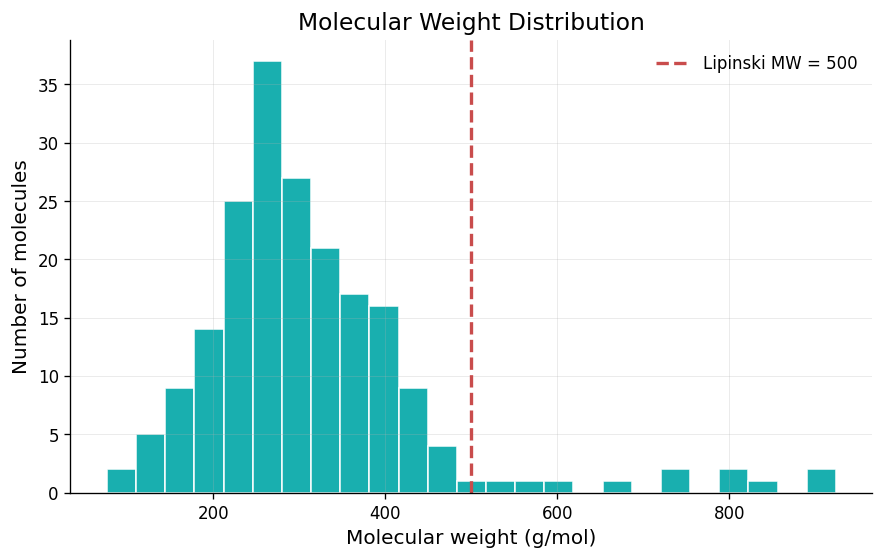

In [26]:
# STEP 14.1 | molecular weight histogram
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.hist(result_df["MW"], bins=25, color=TEAL, edgecolor="white", alpha=0.9)
ax.axvline(500, color=RED, linestyle="--", linewidth=2, label="Lipinski MW = 500")
ax.set_xlabel("Molecular weight (g/mol)")
ax.set_ylabel("Number of molecules")
ax.set_title("Molecular Weight Distribution")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/molecular_weight_distribution.png", bbox_inches="tight")
plt.show()

## 14.2 Lipophilicity–polarity map

### Explanatory note: Lipophilicity versus polarity map
**What it does:** plots cLogP against TPSA, bubble size = MW, colour = risk score, with the cLogP 5 and TPSA 140 limits.

**Why:** this single picture shows the two forces of absorption: getting into membranes (cLogP) and getting out of water (TPSA).

**Real example (reference run):** the high-risk molecules sit above TPSA 140 or right of cLogP 5 (see Figure 1 of the companion manual).

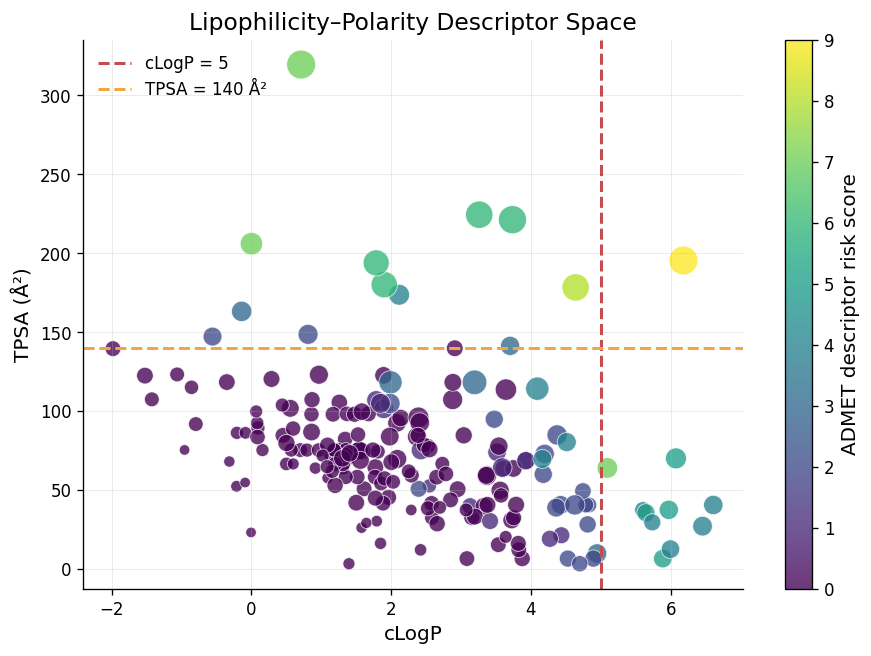

In [32]:
# STEP 14.2 | cLogP vs TPSA descriptor map
fig, ax = plt.subplots(figsize=(7.8, 5.6))
scatter = ax.scatter(
    result_df["cLogP"],
    result_df["TPSA"],
    s=np.clip(result_df["MW"], 120, 900) / 3,
    c=result_df["ADMET_Risk_Score"],
    cmap="viridis",
    alpha=0.78,
    edgecolor="white",
    linewidth=0.5,
)
ax.axvline(5, color=RED, linestyle="--", linewidth=1.8, label="cLogP = 5")
ax.axhline(140, color=ORANGE, linestyle="--", linewidth=1.8, label="TPSA = 140 Å²")
ax.set_xlabel("cLogP")
ax.set_ylabel("TPSA (Å²)")
ax.set_title("Lipophilicity–Polarity Descriptor Space")
cb = fig.colorbar(scatter, ax=ax)
cb.set_label("ADMET descriptor risk score")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/clogp_tpsa_descriptor_space.png", bbox_inches="tight")
plt.show()

## 14.3 Descriptor heatmap

### Explanatory note: Scaled descriptor heatmap
**What it does:** standardises nine descriptors (mean 0, SD 1) and shows the first 40 molecules as a heatmap.

**Why:** scaling puts MW (hundreds) and HBD (single digits) on the same footing, so unusual molecules stand out by colour.

**Real example (reference run):** SIROLIMUS and TACROLIMUS appear as dark red rows for MW, TPSA and HBA.

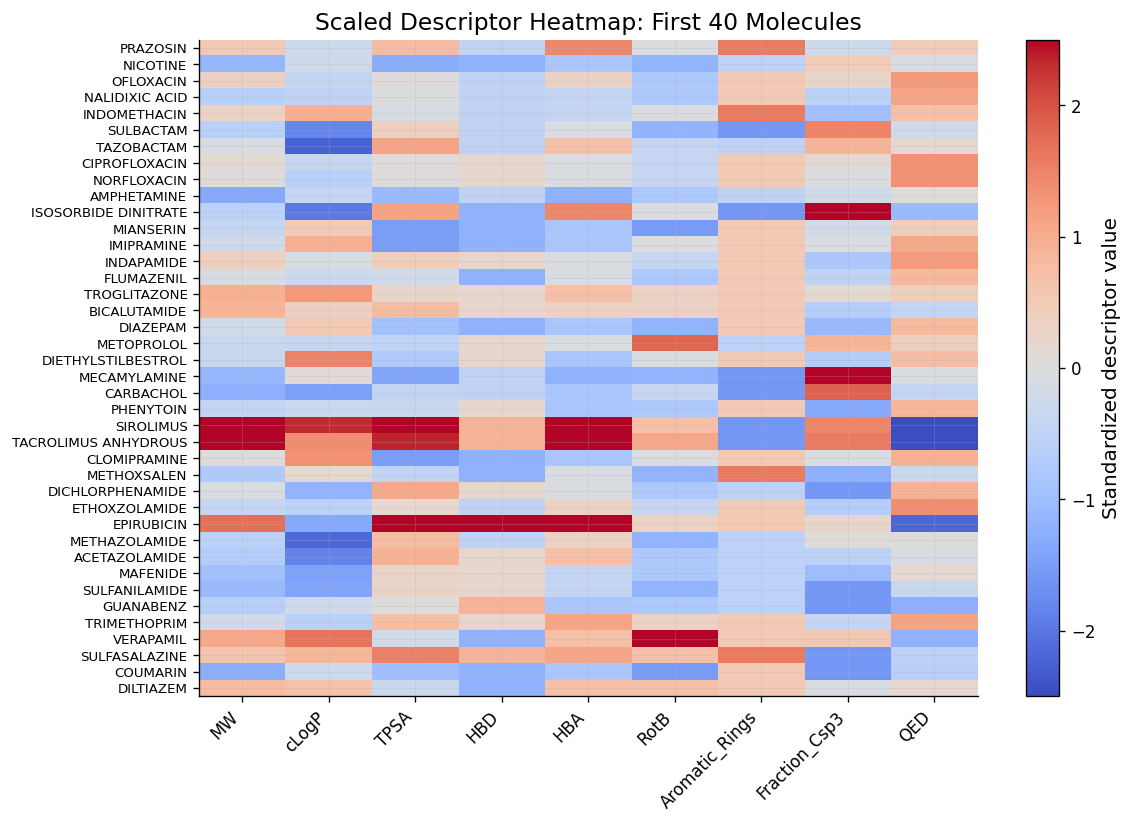

In [33]:
# STEP 14.3 | heatmap of standardised descriptors
heatmap_cols = ["MW", "cLogP", "TPSA", "HBD", "HBA", "RotB", "Aromatic_Rings", "Fraction_Csp3", "QED"]
heatmap_n = min(40, len(result_df))
scaled = StandardScaler().fit_transform(result_df[heatmap_cols])
scaled_df = pd.DataFrame(scaled, columns=heatmap_cols)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(scaled_df.head(heatmap_n).values, aspect="auto", cmap="coolwarm", vmin=-2.5, vmax=2.5)
ax.set_xticks(np.arange(len(heatmap_cols)))
ax.set_xticklabels(heatmap_cols, rotation=45, ha="right")
ax.set_yticks(np.arange(heatmap_n))
ax.set_yticklabels(result_df["Molecule"].head(heatmap_n).astype(str).str.slice(0, 22), fontsize=8)
ax.set_title(f"Scaled Descriptor Heatmap: First {heatmap_n} Molecules")
cb = fig.colorbar(im, ax=ax)
cb.set_label("Standardized descriptor value")
fig.tight_layout()
fig.savefig("figures/scaled_descriptor_heatmap.png", bbox_inches="tight")
plt.show()

## 14.4 PCA chemical descriptor space

### Explanatory note: PCA chemical space
**What it does:** projects the nine scaled descriptors onto two principal components and colours molecules by risk.

**Why:** PCA is unsupervised learning in action: it finds the directions of greatest variation without any labels.

**Real example (reference run):** PC1 explains 41.1 % and PC2 21.7 % of the variance; high-risk molecules separate along PC1.

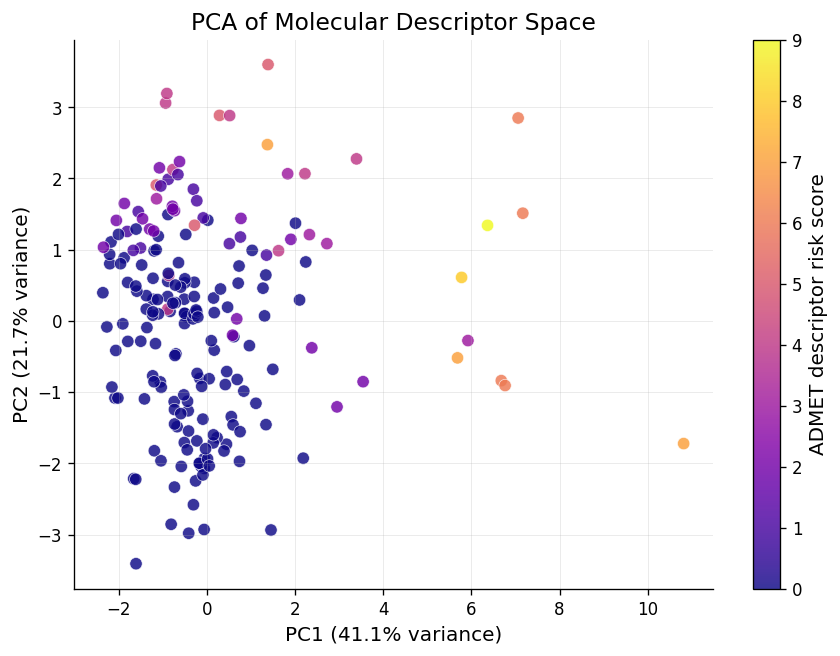

In [29]:
# STEP 14.4 | PCA map of descriptor space
pca_cols = ["MW", "cLogP", "TPSA", "HBD", "HBA", "RotB", "Aromatic_Rings", "Fraction_Csp3", "QED"]
X = StandardScaler().fit_transform(result_df[pca_cols])
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X)

result_df["PC1"] = pcs[:, 0]
result_df["PC2"] = pcs[:, 1]

fig, ax = plt.subplots(figsize=(7.5, 5.6))
sc = ax.scatter(
    result_df["PC1"],
    result_df["PC2"],
    c=result_df["ADMET_Risk_Score"],
    cmap="plasma",
    s=55,
    alpha=0.82,
    edgecolor="white",
    linewidth=0.4,
)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("PCA of Molecular Descriptor Space")
cb = fig.colorbar(sc, ax=ax)
cb.set_label("ADMET descriptor risk score")
fig.tight_layout()
fig.savefig("figures/pca_descriptor_space.png", bbox_inches="tight")
plt.show()

## 14.5 Top and bottom ranked molecules by descriptor risk

### Explanatory note: Best and worst ranked molecules
**What it does:** plots the 10 lowest-risk and 10 highest-risk molecules as a lollipop chart.

**Why:** the lollipop form shows score 0 as a visible dot; the original bar chart left the best molecules invisible.

**Real example (reference run):** lowest risk: PAROXETINE, MOLINDONE, ETHOXZOLAMIDE ...; highest: SIROLIMUS (9), TACROLIMUS (8).

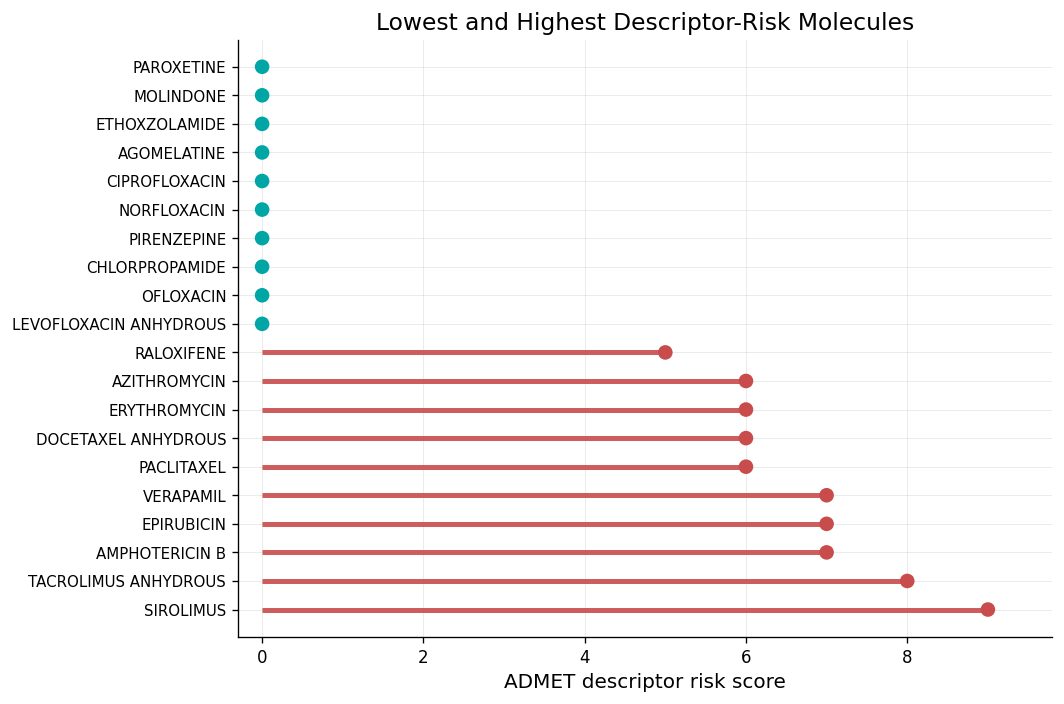

In [34]:
# STEP 14.5 | lowest- and highest-risk molecules
plot_rank = pd.concat([
    ranking_df.head(10),
    ranking_df.tail(10)
]).drop_duplicates("Canonical_SMILES")

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(plot_rank))
colors = [TEAL if s <= 1 else ORANGE if s <= 3 else RED for s in plot_rank["ADMET_Risk_Score"]]
ax.hlines(y_pos, 0, plot_rank["ADMET_Risk_Score"], color=colors, linewidth=3, alpha=0.9)
ax.scatter(plot_rank["ADMET_Risk_Score"], y_pos, color=colors, s=60, zorder=3)
ax.set_xlim(-0.3, plot_rank["ADMET_Risk_Score"].max() + 0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_rank["Molecule"].astype(str).str.slice(0, 28), fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("ADMET descriptor risk score")
ax.set_title("Lowest and Highest Descriptor-Risk Molecules")
fig.tight_layout()
fig.savefig("figures/ranked_admet_risk_score.png", bbox_inches="tight")
plt.show()

## 14.6 Radar plot for selected molecules

The radar plot compares molecules across normalized ADMET-relevant descriptor limits.

### Explanatory note: Radar plot
**What it does:** draws six descriptors of the five top-ranked molecules, each divided by its rule limit (1.0 = at the limit).

**Why:** a radar shows how much safety margin a molecule has on every axis at once.

**Real example (reference run):** all five top molecules stay well inside the limit ring on every axis.

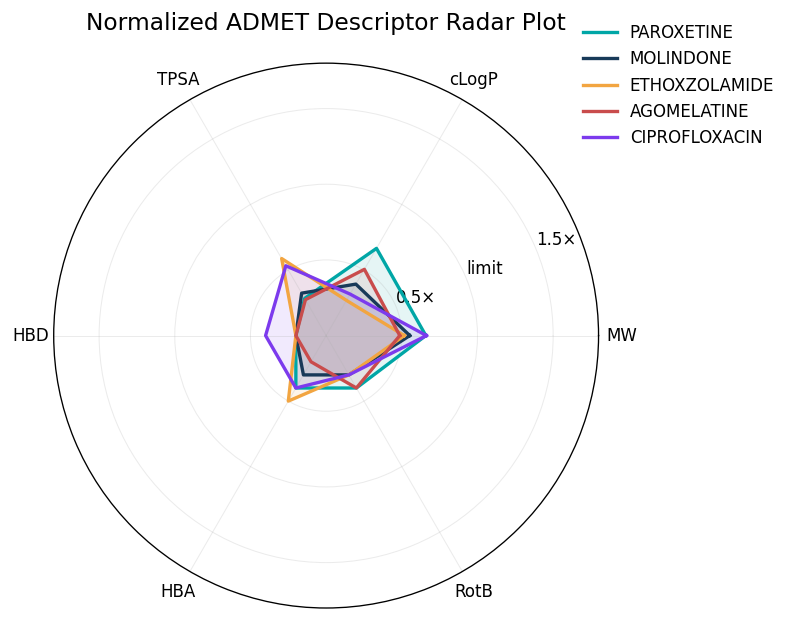

In [35]:
# STEP 14.6 | radar plot of normalised descriptors
def make_radar_plot(df, selected_indices=None, save_path="figures/radar_descriptor_profile.png"):
    radar_features = ["MW", "cLogP", "TPSA", "HBD", "HBA", "RotB"]
    limits = {"MW": 500, "cLogP": 5, "TPSA": 140, "HBD": 5, "HBA": 10, "RotB": 10}

    if selected_indices is None:
        selected_indices = list(df.head(5).index)

    labels = radar_features
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    palette = [TEAL, NAVY, ORANGE, RED, "#7C3AED", "#059669"]

    for j, idx in enumerate(selected_indices):
        row = df.loc[idx]
        values = [min(row[f] / limits[f], 1.8) for f in radar_features]
        values += values[:1]
        ax.plot(angles, values, linewidth=2, color=palette[j % len(palette)], label=str(row["Molecule"])[:20])
        ax.fill(angles, values, color=palette[j % len(palette)], alpha=0.10)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.8)
    ax.set_yticks([0.5, 1.0, 1.5])
    ax.set_yticklabels(["0.5×", "limit", "1.5×"])
    ax.set_title("Normalized ADMET Descriptor Radar Plot", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), frameon=False)
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()

# Use the five lowest-risk molecules for the first radar plot
selected = ranking_df.head(5).index.tolist()
make_radar_plot(ranking_df, selected_indices=selected)

# 15. Interactive Plotly descriptor map

This plot is useful in Colab because students can hover over points to inspect molecule-specific properties.

### Explanatory note: Interactive descriptor map
**What it does:** builds an interactive Plotly version of the cLogP-TPSA map with molecule names on hover.

**Why:** hovering lets students identify outliers by name during discussion.

**Real example (reference run):** saved as `figures/interactive_admet_descriptor_map.html`.

In [36]:
# STEP 15 | interactive Plotly map
fig = px.scatter(
    result_df,
    x="cLogP",
    y="TPSA",
    size="MW",
    color="ADMET_Decision",
    hover_name="Molecule",
    hover_data=["MW", "HBD", "HBA", "RotB", "Lipinski_Violations", "Veber_Pass", "ADMET_Risk_Score"],
    title="Interactive ADMET Descriptor Map",
    width=900,
    height=600,
)
fig.add_vline(x=5, line_dash="dash", line_color="red")
fig.add_hline(y=140, line_dash="dash", line_color="orange")
fig.write_html("figures/interactive_admet_descriptor_map.html")
fig.show()

# 16. Create a Day 3 ML-ready feature table

This section generates Morgan fingerprints that can be used in the Day 3 ML workshop.

### Explanatory note: ML-ready feature table
**What it does:** adds 2048-bit Morgan fingerprints (radius 2) to nine descriptors.

**Why:** this is the exact feature format the Day 3 activity models use, so Day 2 output feeds Day 3.

**Real example (reference run):** feature table shape (198, 2061).

In [8]:
# STEP 16 | build the ML-ready feature matrix for Day 3
from rdkit.Chem import rdFingerprintGenerator

fp_size = 2048
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=fp_size)


def morgan_fp_array(mol):
    fp = morgan_gen.GetFingerprint(mol)
    arr = np.zeros((fp_size,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fp_matrix = np.vstack(clean_df["Mol"].apply(morgan_fp_array).values)
fp_df = pd.DataFrame(fp_matrix, columns=[f"Morgan_{i}" for i in range(fp_size)])

ml_ready_df = pd.concat([
    result_df[["Molecule", "Canonical_SMILES", "ADMET_Risk_Score", "ADMET_Decision"]].reset_index(drop=True),
    result_df[["MW", "cLogP", "TPSA", "HBD", "HBA", "RotB", "Aromatic_Rings", "Fraction_Csp3", "QED"]].reset_index(drop=True),
    fp_df.reset_index(drop=True)
], axis=1)

print(ml_ready_df.shape)
display(ml_ready_df.iloc[:5, :15])

ModuleNotFoundError: No module named 'rdkit'

# 17. Export results

The notebook exports:

- Full descriptor table
- Candidate ranking table
- ML-ready descriptor + fingerprint table
- Static figures
- Interactive HTML figure
- A short Markdown summary

### Explanatory note: Export
**What it does:** writes the descriptor table, ranking, ML features, an Excel workbook and a markdown summary.

**Why:** results must leave the notebook in standard formats for reports and for Day 3.

**Real example (reference run):** `outputs/ADMET_Day2_results.xlsx` with sheets Descriptors, Ranking and Invalid_SMILES.

In [5]:
# STEP 17 | export all tables
# Remove non-serializable molecule objects before export.
export_df = result_df.copy()

# Convert alert lists to strings for CSV/Excel export
for col in ["Lipinski_Alerts", "Veber_Alerts"]:
    if col in export_df.columns:
        export_df[col] = export_df[col].apply(lambda x: "; ".join(x) if isinstance(x, list) else str(x))

ranking_export_df = ranking_df.copy()
for col in ["Lipinski_Alerts", "Veber_Alerts"]:
    if col in ranking_export_df.columns:
        ranking_export_df[col] = ranking_export_df[col].apply(lambda x: "; ".join(x) if isinstance(x, list) else str(x))

export_df.to_csv("outputs/ADMET_descriptor_results.csv", index=False)
ranking_export_df.to_csv("outputs/ADMET_candidate_ranking.csv", index=False)
ml_ready_df.to_csv("outputs/ADMET_ML_ready_features.csv", index=False)

# Excel workbook with key tables
with pd.ExcelWriter("outputs/ADMET_Day2_results.xlsx") as writer:
    export_df.to_excel(writer, sheet_name="Descriptors", index=False)
    ranking_export_df[rank_cols].to_excel(writer, sheet_name="Ranking", index=False)
    invalid_df.drop(columns=[c for c in ["Mol_raw", "Mol"] if c in invalid_df.columns]).to_excel(writer, sheet_name="Invalid_SMILES", index=False)

summary_text = f'''# ADMET Day 2 Colab Summary

Input mode: {INPUT_MODE}

Original molecules: {len(raw_df)}
Clean unique molecules: {len(clean_df)}
Invalid molecules removed: {len(invalid_df)}

## Descriptor-risk categories

{export_df['ADMET_Decision'].value_counts().to_string()}

## Top 10 lowest-risk molecules

{ranking_export_df[['Molecule', 'MW', 'cLogP', 'TPSA', 'Lipinski_Violations', 'Veber_Pass', 'ADMET_Risk_Score', 'Main_Risk']].head(10).to_markdown(index=False)}

## Important note

The ADMET risk score in this notebook is an educational descriptor-based score. It is not a validated endpoint-specific ADMET prediction model.
'''

with open("outputs/ADMET_Day2_summary.md", "w") as f:
    f.write(summary_text)

print("Exported results to outputs/ and figures/ folders.")

NameError: name 'result_df' is not defined

## 18. Download all outputs as a ZIP file

### Explanatory note: Download outputs
**What it does:** zips `outputs/` and `figures/` and downloads the ZIP on Colab.

**Why:** students leave the class with every result file.

**Real example (reference run):** `ADMET_Day2_Colab_outputs.zip` (about 1.5 MB).

In [ ]:
# STEP 18 | zip and download everything
zip_path = "ADMET_Day2_Colab_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in ["outputs", "figures"]:
        for root, dirs, files_in_dir in os.walk(folder):
            for file in files_in_dir:
                path = os.path.join(root, file)
                zipf.write(path, arcname=path)

print(f"Created {zip_path}")

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download manually from the file browser if not running in Google Colab.")

# 19. Student interpretation exercise

Use the output tables and plots to answer these questions:

1. Which molecules passed both Lipinski and Veber filters?
2. Which molecules showed the strongest solubility-risk flags?
3. Which molecules showed the strongest permeability-risk flags?
4. Which molecules are possible BBB-penetrant candidates by descriptor proxy?
5. Which five molecules have the lowest descriptor-based ADMET risk score?
6. Which five molecules should be deprioritized first?
7. Which descriptor contributed most strongly to the risk of the highest-risk molecules?
8. Which molecules would you select for more detailed ADMET prediction or experimental testing?

Final student output table:

| Molecule | Main ADMET strength | Main ADMET risk | Decision |
|---|---|---|---|
| Example | Lipinski acceptable | high cLogP | Modify |

# 20. Final teaching message

This notebook demonstrates a complete **Colab-based ADMET calculation pipeline**:

\[
\text{ChEMBL or uploaded SMILES}
\rightarrow
\text{structure cleaning}
\rightarrow
\text{molecule visualization}
\rightarrow
\text{descriptor calculation}
\rightarrow
\text{Lipinski/Veber filtering}
\rightarrow
\text{ADMET proxy flags}
\rightarrow
\text{plots and ranking}
\rightarrow
\text{ML-ready feature table}
\]

The goal is not to produce a final clinical ADMET answer. The goal is to teach students how to turn chemical structures into interpretable, reproducible, and visually clear computational ADMET evidence.